Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8944 - loss: 0.3806 - val_accuracy: 0.9542 - val_loss: 0.1725
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9504 - loss: 0.1749 - val_accuracy: 0.9667 - val_loss: 0.1251
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9642 - loss: 0.1243 - val_accuracy: 0.9725 - val_loss: 0.0996
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9727 - loss: 0.0961 - val_accuracy: 0.9737 - val_loss: 0.0890
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9782 - loss: 0.0775 - val_accuracy: 0.9765 - val_loss: 0.0830
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9754 - loss: 0.0892  

Test Accuracy: 0.9753999710083008
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 804us/step

Accuracy : 0.9754
Precision: 0.9754723730313483
Recall   : 0.9754
F1 Score : 0.9753821245411837


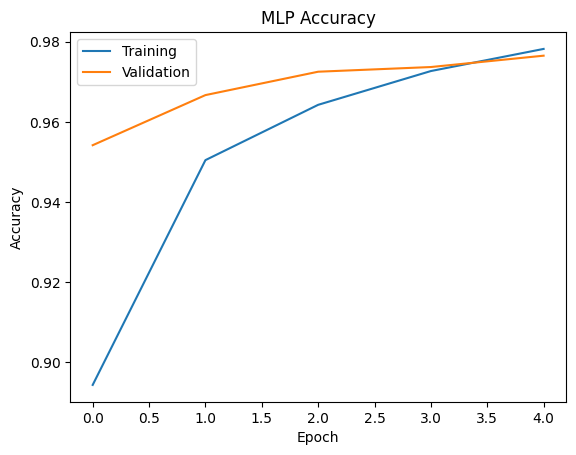

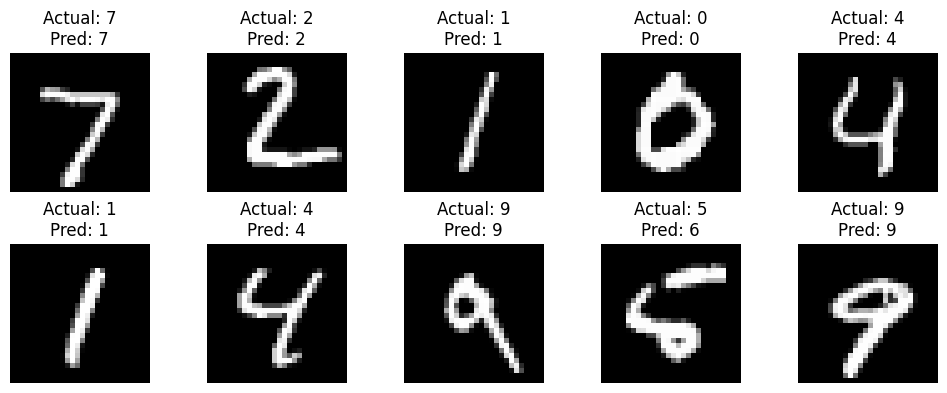

In [2]:

import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Load dataset
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

# Normalize
x_train = x_train / 255.0
x_test = x_test / 255.0

# Create MLP
model = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

# Compile
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Train
history = model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=128,
    validation_split=0.1
)

# Test
loss, accuracy = model.evaluate(x_test, y_test)

print("\nTest Accuracy:", accuracy)

# Predictions
y_prob = model.predict(x_test)
y_pred = y_prob.argmax(axis=1)

# Metrics
print("\nAccuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, average="weighted"))
print("Recall   :", recall_score(y_test, y_pred, average="weighted"))
print("F1 Score :", f1_score(y_test, y_pred, average="weighted"))

# Accuracy plot
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("MLP Accuracy")
plt.legend()
plt.show()

# Actual vs Predicted
plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i], cmap="gray")
    plt.title(
        f"Actual: {y_test[i]}\nPred: {y_pred[i]}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()